# 7. Routing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/07_routing.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/07_routing.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-7.svg" alt="duckOSM notebook manual, chapter 7: Routing" width="100%">

| **You learn** | the turn graph; the three kinds of place; a route between edges, points and names; the fastest and the shortest route; the turn-by-turn steps; a route across modes; the graph in networkx and rustworkx |
|---|---|
| **Time** | about 3 minutes |
| **Extras** | `duckosm[widget,viz,graph]` (the install cell installs them) |
| **Next** | [8. Advanced routing](08_routing_advanced.md): the Route object, many routes, the k best routes, the matrix and isochrones |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz,graph] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## How duckOSM finds a route

A road network looks like a graph of junctions and roads. But a route on that graph can break the rules of the
real road: it can turn left where a sign forbids it, or make a U-turn in the middle of a junction. To obey the turn
rules, duckOSM routes on another graph, the **turn graph** (also called the edge graph):

| In the turn graph | Is |
|---|---|
| a node | one edge of the network (one direction of a road), with its `edge_id` |
| an arc | a legal turn from one edge to the next edge: the turn restrictions of OSM and the one-way rules are in it |
| the cost of an arc | the time (`cost_s`) or the length (`length_m`) of the edge before the turn |

The table `<mode>.edge_graph` of the database holds the arcs. The picture shows one junction. The road from the
west (edge 1) has a sign "no left turn". In the turn graph, edge 1 has an arc to edge 2 and to edge 3, but no arc to
edge 4. So a route cannot make that turn.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/turn-graph.svg" alt="A junction and its turn graph: each edge is a node, each legal turn is an arc, the forbidden left turn has no arc" width="100%">

The search is a bidirectional Dijkstra search, in Rust. One route in Monaco takes about 40 ms.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> A route goes from edge to edge on the turn graph. Each arc is a legal turn, so every route of duckOSM obeys the turn restrictions and the one-way rules of its mode.

## The three kinds of place

Each routing call takes its start and its end as a **place**. A place is one of three things:

| Place | Example | How it joins the network |
|---|---|---|
| an edge id | `240162084728701473` | that edge: the route starts at the start of the edge and ends at the end of the edge |
| a `(lon, lat)` point | `(7.4155, 43.7285)` | the nearest road within `radius_m`, plus the walk from the point to the road |
| a place name | `"Boulevard Albert 1er"` | the middle of the longest edge with that name; else the first answer of Nominatim in the box of the network |

A point is `(lon, lat)`, in this order, as in GeoJSON. Write a point with decimals: two integers, for example
`(7, 43)`, are not a point.

## Build Monaco with three modes and the multimodal graph

This chapter routes by car, on foot and across modes. A route across modes needs the **multimodal graph**: the
tables `mm.*`, which join the networks of the modes at their shared junctions. The build makes them only when the
config says so, so the cell gives `config=` with `multimodal: {enabled: true}` (chapter 1, "Every other option").

In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], name="monaco",
                      config={"multimodal": {"enabled": True}})       # three modes and the multimodal graph
net.summary()                                                         # one row for each mode

cut: 34461 nodes, 5685 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco-20261120-194330-46ee/monaco.duckdb

,mode,edges,nodes,km,oneway_km
0,driving,2840,1768,96.2,35.5
1,walking,11938,4589,260.6,0.0
2,cycling,11305,4650,250.0,35.5


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The file has three networks: 2,840 driving edges, 11,938 walking edges and 11,305 cycling edges. The `mm` tables are not in the summary, because they join the three modes and are not a mode.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The same build from a config file: write the keys to `monaco.yaml` (`modes: [driving, walking, cycling]`, `multimodal: {enabled: true}`) and call `duckosm.build(config="monaco.yaml")`. The file `config/template.yaml` of the repository lists every key.

## One call, three ways to write it

The routing calls are functions of the module `duckosm.routing`. Each function is also a method of the network and
of a mode view. These three lines give the same route:

| Form | When to use it |
|---|---|
| `net.driving.route(a, b)` | the short form: the mode view gives the mode |
| `net.route(a, b, mode="driving")` | the mode is in a variable |
| `duckosm.routing.route(net.driving, a, b)` | in a library, or with a path or a DuckDB connection in place of the network |

With a path or a connection, the default mode is `"driving"`. The rest of the chapter uses the short form.

## Between two roads

A route between two edge ids is the most direct call: no point to join, no name to find. The cell takes one edge of
Boulevard du Larvotto and one edge of Avenue Princesse Grace from the table `driving.edges`, then finds the fastest
route between them.

In [3]:
q = "SELECT min(edge_id) AS edge_id FROM driving.edges WHERE name = ?"
start = int(net.sql(q, ["Boulevard du Larvotto"]).edge_id[0])    # one edge of Boulevard du Larvotto
end = int(net.sql(q, ["Avenue Princesse Grace"]).edge_id[0])     # one edge of Avenue Princesse Grace
r = net.driving.route(start, end)                                # the fastest route from edge to edge
r                                                                # a Route: the card shows the edges, the length and the time

edges,29
length,"1,513 m"
time,1.9 min


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The route from Boulevard du Larvotto to Avenue Princesse Grace has 29 edges, 1,513 m, and takes 1.9 minutes (114 s). The card gives the time in minutes.

The result is a `Route`. `r.edge_ids` is its list of edges, `r.time_s` and `r.length_m` are its sums. Chapter 8 shows
all the parts of a `Route`. When no route connects the two places (for example an edge that has no exit), the call
gives `None`.

In [4]:
r.edge_ids[:3], round(r.time_s, 1), round(r.length_m)     # the first three edges, the seconds and the metres

([326733873067431220, 4454987030486000106, 3487789174266503140], 114.1, 1513)

## Between two points

### `route` with two points

With two `(lon, lat)` points, `route` joins each point to its nearest road. The time of the route includes the walk
from the point to the road, at 4.5 km/h. The cell finds the route from Fontvieille to Larvotto by car and on foot.

In [5]:
a, b = (7.4155, 43.7285), (7.4335, 43.7468)    # Fontvieille and Larvotto
drive = net.driving.route(a, b)                # by car
walk = net.walking.route(a, b)                 # on foot
round(drive.time_s / 60, 1), round(walk.time_s / 60, 1)          # the two times in minutes

(3.8, 36.4)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The car takes 3.8 minutes and the walk takes 36.4 minutes. Each time includes the short walk from the point to its nearest road.

### `route_points`: the options of the join

`route` with two points calls `route_points`. Call it yourself to set the options of the join:

| Argument | Default | Does |
|---|---|---|
| `radius_m` | `50.0` | the largest distance from the point to its road, in metres; no road nearer: `None` |
| `access_kmh` | `4.5` | the speed of the walk from the point to the road |
| `weight` | `"time"` | `"time"`: the fastest route; `"length"`: the shortest |

The `Route` of `route_points` also has `start` and `end`: where each point joins the road.

In [6]:
p = net.driving.route_points(a, b, radius_m=100, access_kmh=5)     # a larger radius, a faster walk
{k: (round(v, 6) if isinstance(v, float) else v) for k, v in p["start"].items()}    # where the first point joins

{'point': [7.4155, 43.7285],
 'road_point': [7.415562, 43.728580900000004],
 'edge_id': 4226571288485271664,
 'fraction': 0.0,
 'access_m': 10.294595,
 'access_s': 7.412108}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The first point joins the road at `road_point`, 10.3 m away (`access_m`). The walk to the road takes 7.4 s at 5 km/h (`access_s`). `edge_id` is the first edge of the route, and `fraction` is where the point joins it: 0.0 is the start of the edge, 1.0 its end.

## Between two place names

A place can be a street name. `duckosm.routing.geocode` turns the name into a point. It first looks in the network:
the point is the middle of the longest edge with that name. When the network has no road with the name, it asks
Nominatim (the search of OpenStreetMap, on the internet) for a place in the box of the network.

In [7]:
duckosm.routing.geocode(net.driving, "Boulevard Albert 1er")    # the (lon, lat) of a street name

(7.421134960833079, 43.73590722783044)

In [8]:
by_name = net.driving.route("Boulevard Albert 1er", "Avenue Princesse Grace")    # from street to street
by_name

edges,33
length,"1,350 m"
time,2.0 min


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The point of Boulevard Albert 1er is (7.4211, 43.7359), in the middle of the longest edge of the street. The route by name has 33 edges, 1,350 m, and takes 122 s.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> A name gives one point. A long street has many points, and the route starts at the middle of its longest edge. Use a point or an edge id when the exact start is important.

## The fastest or the shortest route

`weight` chooses what the search makes small:

| `weight` | The cost of an edge | The route |
|---|---|---|
| `"time"` (the default) | `cost_s`, the travel time from the length and the speed | the fastest |
| `"length"` | `length_m` | the shortest |

In [9]:
fast = net.driving.route(a, b)                       # the fastest route
short = net.driving.route(a, b, weight="length")     # the shortest route
[(round(x.time_s), round(x.length_m)) for x in (fast, short)]    # seconds and metres of each

[(229, 2939), (236, 2937)]

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The fastest route takes 229 s for 2,939 m. The shortest route is only 2 m shorter (2,937 m), but it takes 236 s, 7 s more. In a small city the two routes are almost the same. In a large area, the fastest route often takes a motorway that is longer but much faster.

## Draw routes on the map

`net.map(routes=...)` draws routes on the roadstyle map of the network. `routes` is a dict: each name becomes an item
of the legend, and each route gets its own color. Run the cell to see the live map: you can zoom, and click a road
to see its columns. The manual page shows a picture of the map.

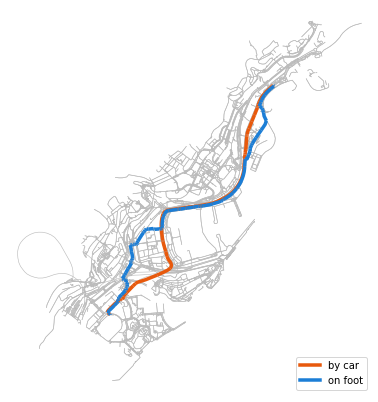

In [10]:
net.map(routes={"by car": drive, "on foot": walk})    # the two routes as lines on the map

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The car route uses the tunnels and the large boulevards along the coast. The walking route is more direct: it uses the steps and footways that a car cannot use.

## Turn-by-turn steps

`route.directions()` gives the steps of a route, as a navigation app says them. Each step is a dict:

| Key | Is |
|---|---|
| `text` | the step in words |
| `type` | `depart`, `turn`, `roundabout`, `continue`, `arrive` ... |
| `modifier` | the direction of the turn: `left`, `right`, `straight` ... |
| `name` | the name of the road after the step |
| `length_m` | the length of the road until the next step |
| `at` | the point of the step, `(lon, lat)` |

`duckosm.routing.directions(net.driving, r)` and `net.driving.directions(r)` give the same steps.

In [11]:
[step["text"] for step in drive.directions()]               # one step for each turn of the car route

['Head northwest on Avenue des Castelans',
 'At the roundabout, take the 1st exit onto Avenue Albert II',
 'At the roundabout, take the 3rd exit onto Avenue Albert II',
 'Continue onto Tunnel Rocher Palais',
 'Continue onto Tunnel Rocher Albert Ier',
 'Continue onto Tunnel Rocher Palais',
 'Continue onto Boulevard Albert 1er',
 'At the roundabout, take the 1st exit onto Avenue John F. Kennedy',
 'Continue onto Boulevard Louis II',
 'At the roundabout, take the 2nd exit onto Avenue Princesse Grace',
 'Arrive at your destination']

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The car route has eleven steps, from "Head northwest on Avenue des Castelans" to "Arrive at your destination". A roundabout step gives the number of the exit. A new street name gives a "Continue onto" step, also in the tunnels.

## The graph of each mode

The table `<mode>.edge_graph` can hold arcs that the mode does not use, for example the turns that only a bus can make.
`duckosm.routing.routed_graph(view)` gives the SQL of the arcs that the mode routes on. Use it in your own SQL to work
on the same graph as the routes.

In [12]:
g_sql = duckosm.routing.routed_graph(net.driving)             # the arcs that a car route can use
net.sql(f"SELECT (SELECT count(*) FROM driving.edge_graph) AS all_arcs, (SELECT count(*) FROM {g_sql}) AS car_arcs")

,all_arcs,car_arcs
0,6754,5082


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> `driving.edge_graph` has 6,754 arcs, but a car can use only 5,082 of them. The other arcs are turns for buses and other vehicles. Every routing call of the driving mode uses the 5,082 arcs.

## Across modes

### Between two points

`net.route_multimodal_points(a, b)` finds the fastest trip that can change mode: walk to a car, drive, and walk from
the car. It routes on the multimodal graph:

| Part | Is |
|---|---|
| a leg | one part of the trip in one mode, with its edges, its seconds and its metres |
| a transfer | a change of mode at a shared junction: `park`, `retrieve` (driving), `bike_park`, `bike_unpark` (cycling); each costs 60 s |

A trip starts and ends on foot, and it has one vehicle leg at most (`enforce_sequence=True`). Each leg obeys the turn
rules of its mode.

In [13]:
m = net.route_multimodal_points(a, b)                                        # the fastest trip with any of the modes
[(leg["mode"], len(leg["edges"]), round(leg["time_s"])) for leg in m["legs"]], round(m["time_s"])    # each leg; the total seconds

([('walking', 1, 3), ('driving', 75, 220), ('walking', 1, 0)], 350)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The trip has three legs: a walk on 1 edge (3 s), a drive on 75 edges (220 s) and a walk on 1 edge (0 s). The total is 350 s. It includes two transfers of 60 s, into the car and out of it, and the walks from the points to the roads. Here the car-only route takes 229 s, so the trip across modes is slower: the two transfers cost 120 s.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> The multimodal graph has a car waiting at each shared junction, and no public transport (OSM has no timetables). Use it to compare the modes, not as a trip planner.

`allowed_modes` limits the trip to some modes. A trip between two points must include `walking`. Here the trip
has no car: it can walk and cycle.

In [14]:
bike = net.route_multimodal_points(a, b, allowed_modes=["walking", "cycling"])     # a trip without a car
[(leg["mode"], len(leg["edges"]), round(leg["time_s"])) for leg in bike["legs"]], round(bike["time_s"])

([('walking', 1, 0), ('cycling', 76, 705), ('walking', 1, 0)], 830)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The trip without a car cycles on 76 edges for 705 s. The total is 830 s (13.8 minutes), with the two transfers of the bicycle. The walk alone takes 36.4 minutes, so the bicycle is much faster.

### Between two junctions

`duckosm.routing.route_multimodal(net, src_node, dst_node)` is the same search between two junctions, by their
`node_id`. It has the arguments `start_mode` and `end_mode` (default `"walking"`), `allowed_modes` and
`enforce_sequence`. The result has the same legs, and also the list of transfers.

In [15]:
ends = net.sql("SELECT min(node_id) AS a, max(node_id) AS b FROM walking.nodes WHERE node_id > 0")    # two OSM junctions
j = duckosm.routing.route_multimodal(net, int(ends.a[0]), int(ends.b[0]))                          # from junction to junction
[(leg["mode"], round(leg["time_s"])) for leg in j["legs"]], [t["kind"] for t in j["transfers"]]

([('driving', 195), ('walking', 38)], ['park', 'retrieve'])

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The trip has two legs: a drive (195 s) and a walk (38 s), with two transfers, `park` and `retrieve`. The trip starts at a junction where a car can wait, so it changes to the car at once, with no walking leg before it.

## As a graph

The turn graph is also a graph object for your own algorithms:

| Call | Gives | Needs |
|---|---|---|
| `net.driving.to_networkx()` | a `networkx.DiGraph`: a node is an `edge_id`, an arc a legal turn with its `weight` | `networkx` |
| `net.driving.to_rustworkx()` | the same graph as a `rustworkx.PyDiGraph`; `g.attrs["index"]` gives the node index of an `edge_id` | `rustworkx` |

Both take `weight="time"` (seconds) or `weight="length"` (metres). The weight of an arc is the cost of the edge before
the turn. So the cost of a path in the graph does not include the last edge, and the route adds it.

In [16]:
import networkx as nx

g = net.driving.to_networkx()                                      # the turn graph of the driving network
g.number_of_nodes(), g.number_of_edges(), nx.shortest_path(g, start, end, weight="weight") == r.edge_ids    # the same path as the route

(2840, 5082, True)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The networkx graph has 2,840 nodes (one for each driving edge) and 5,082 arcs (the turns that a car can make). Its shortest path between the two edges is the path of the route: `True`.

In [17]:
import rustworkx as rx

h = net.driving.to_rustworkx()                                     # the same graph in rustworkx
ix = h.attrs["index"]                                              # the node index of each edge_id
graph_s = rx.dijkstra_shortest_path_lengths(h, ix[start], edge_cost_fn=float, goal=ix[end])[ix[end]]    # the shortest time in the graph
last_s = float(net.sql("SELECT cost_s FROM driving.edges WHERE edge_id = ?", [end]).cost_s[0])        # the time of the last edge
round(graph_s, 1), round(graph_s + last_s, 1), round(r.time_s, 1)                                    # graph, graph + last edge, route

(113.2, 114.1, 114.1)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The shortest time in the rustworkx graph is 113.2 s. With the time of the last edge, it is 114.1 s, the time of the route.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> Use networkx for its many algorithms on a small area, and rustworkx for speed on a large area. For many routes or a travel time matrix, the calls of chapter 8 run in Rust and are faster than both.

## What chapter 8 adds

This chapter finds one route at a time. [8. Advanced routing](08_routing_advanced.md) uses the same turn graph for
more:

| Call | Gives |
|---|---|
| the `Route` object | the edges as a GeoDataFrame, the geometry, a map of the route |
| `routes` | many routes, in parallel |
| `k_shortest_paths` | the next best routes |
| `matrix` | the travel time from each origin to each destination |
| `isochrones`, `accessibility` | the area that you reach in a time, and the targets in reach |

## Try it yourself

**1.** Find the fastest route by bicycle from Fontvieille to Larvotto, and compare its time with the car route.

<details><summary>Show the answer</summary>

```python
bike_route = net.cycling.route(a, b)
round(bike_route.time_s / 60, 1), round(drive.time_s / 60, 1)    # minutes by bicycle and by car
```
</details>

**2.** Find a walking route between two street names, and print its first three steps.

<details><summary>Show the answer</summary>

```python
w = net.walking.route("Boulevard Albert 1er", "Avenue de la Costa")
[s["text"] for s in w.directions()][:3]
```
</details>

**3.** Find the length in km of the shortest walk from Fontvieille to Larvotto with networkx, on the graph with `weight="length"`, between the edges of the route `walk`.

<details><summary>Show the answer</summary>

```python
gw = net.walking.to_networkx(weight="length")
s, t = walk.edge_ids[0], walk.edge_ids[-1]
nx.shortest_path_length(gw, s, t, weight="weight") / 1000      # without the last edge
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| route | a list of edges from a start to an end, with its time and its length |
| turn graph | the graph whose nodes are edges and whose arcs are legal turns (`<mode>.edge_graph`) |
| arc | one legal turn from an edge to the next edge |
| place | the start or the end of a route: an edge id, a `(lon, lat)` point or a name |
| weight | what the search makes small: `time` (seconds) or `length` (metres) |
| geocode | to find the point of a place name |
| multimodal graph | the tables `mm.*`: the networks of the modes, joined at shared junctions |
| leg | the part of a trip in one mode |
| transfer | a change of mode at a junction, for example `park` |

## Summary

| Call | Does |
|---|---|
| `net.driving.route(a, b, weight="time")` | the fastest (or shortest) route between two places; a `Route` or `None` |
| `net.driving.route_points(a, b, radius_m=50, access_kmh=4.5)` | the route between two points, with the options of the join |
| `duckosm.routing.geocode(view, name)` | the `(lon, lat)` of a place name |
| `route.directions()`, `duckosm.routing.directions(view, route)` | the turn-by-turn steps |
| `net.map(routes={...})` | routes on the map |
| `duckosm.routing.routed_graph(view)` | the SQL of the arcs that the mode routes on |
| `net.route_multimodal_points(a, b, allowed_modes=None)` | a trip across modes between two points |
| `duckosm.routing.route_multimodal(net, src_node, dst_node)` | a trip across modes between two junctions |
| `net.driving.to_networkx()`, `net.driving.to_rustworkx()` | the turn graph as a graph object |

The reference: [duckosm.routing](../reference/sdk/routing.md). **Next:** [8. Advanced routing](08_routing_advanced.md), the Route object, many routes, the k best routes, the matrix and isochrones.